In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/ColabNotebooks/IS110_Bperformance_Clarito

/content/drive/MyDrive/ColabNotebooks/IS110_Bperformance_Clarito


---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The objective is to predict whether a breast tumour is malignant or benign using 30 numerical features derived from the digitised images of fine needle aspirates. It's a classic supervised binary classification problem with the dataset containing examples of both malignant and benign tumours. A false negative (ex. a malignant tumour being predicted as benign) is the more serious of the two errors as it would mean the patient wouldn't get the diagnosis and treatment they needed. The evaluation will be on accuracy, precision, recall, F1 and particularly recall for the malignant cases to ensure we're detecting as many malignant tumours as possible.

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [6]:
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [7]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape of dataset:", df.shape)
print("\nCounts of each data type:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows:")
display(df.head())

Shape of dataset: (569, 31)

Counts of each data type:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [8]:
# TODO: class counts and percentages

print("")

**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [9]:
# TODO: describe().T, then the 10 largest skewness values

df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [10]:
# TODO: correlation with target, sorted
correlations = df.corrwith(df['target']).drop('target').sort_values()

print("5 most negative correlations with target:")
print(correlations.head(5))

print("\n5 most positive correlations with target:")
print(correlations.tail(5))

5 most negative correlations with target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
dtype: float64

5 most positive correlations with target:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:**

**The Situation**: The dataset is moderately imbalanced with roughly 62.7% benign (Class 1) and 37.3% malignant (Class 0) cases.

**Metric Selection**: Because of this imbalance, relying solely on Accuracy can be misleading (a naive model predicting everything as benign would still get over 62% accuracy). Since diagnosing a malignant tumor as benign (False Negative) is highly costly, we need metrics that focus on class-specific performance.

**Recommendation**: You should prioritize Recall (Sensitivity) for the malignant class to minimize false negatives, alongside F1-Score or Precision-Recall AUC (PR-AUC) to maintain a balance and ensure the model does not overpredict malignancy.

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

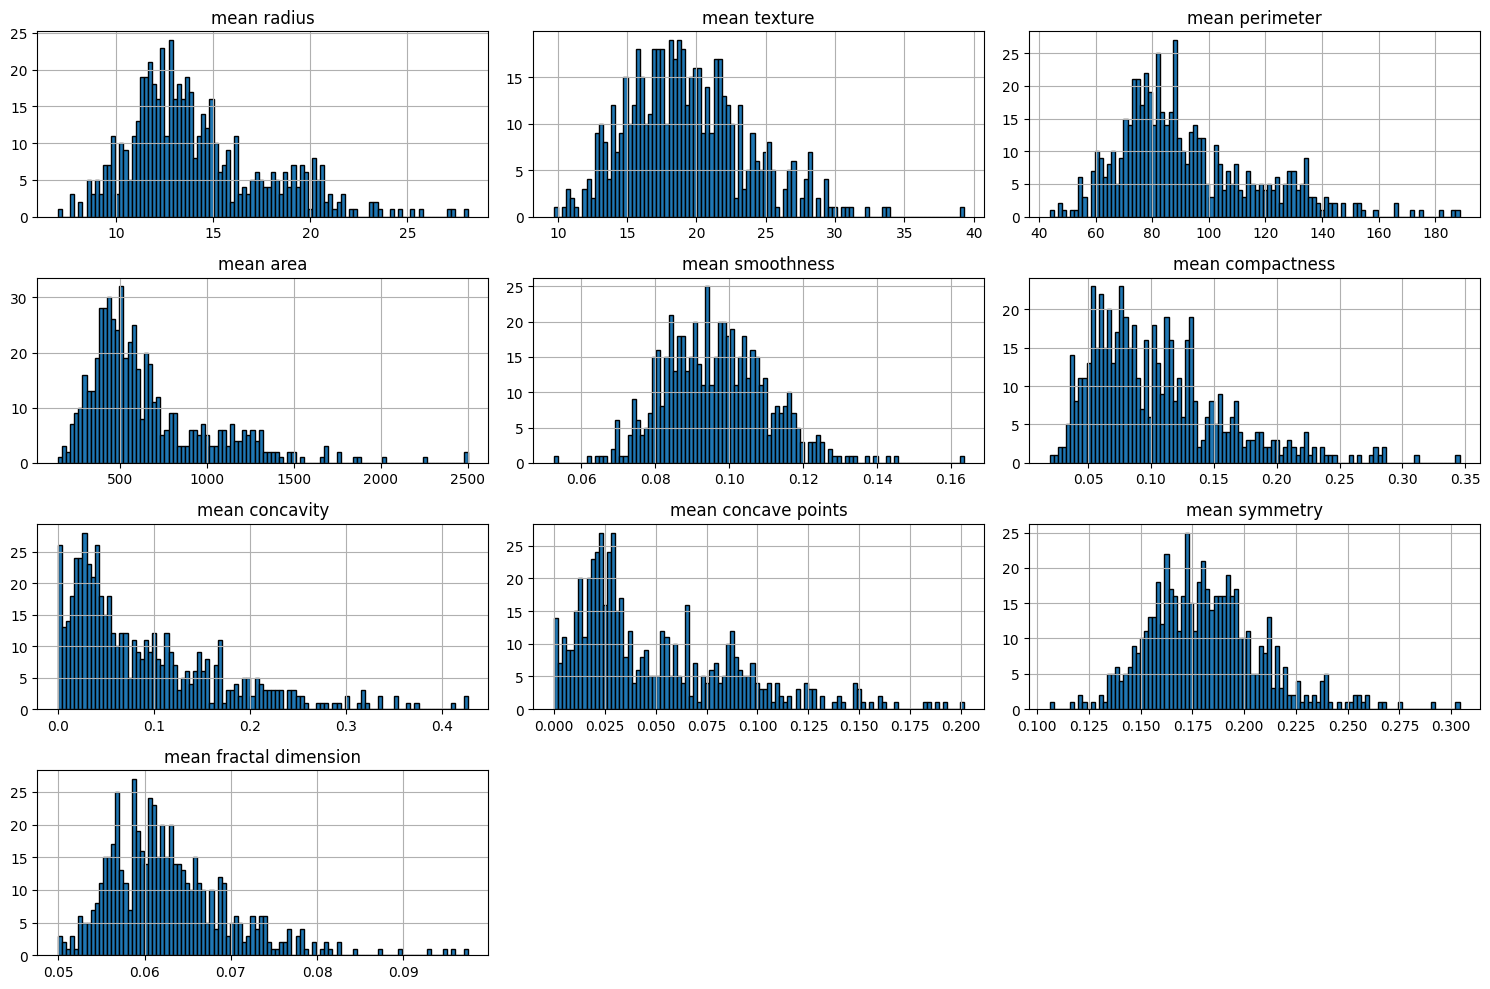

In [11]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist(figsize=(15, 10), bins=100, edgecolor='black')
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

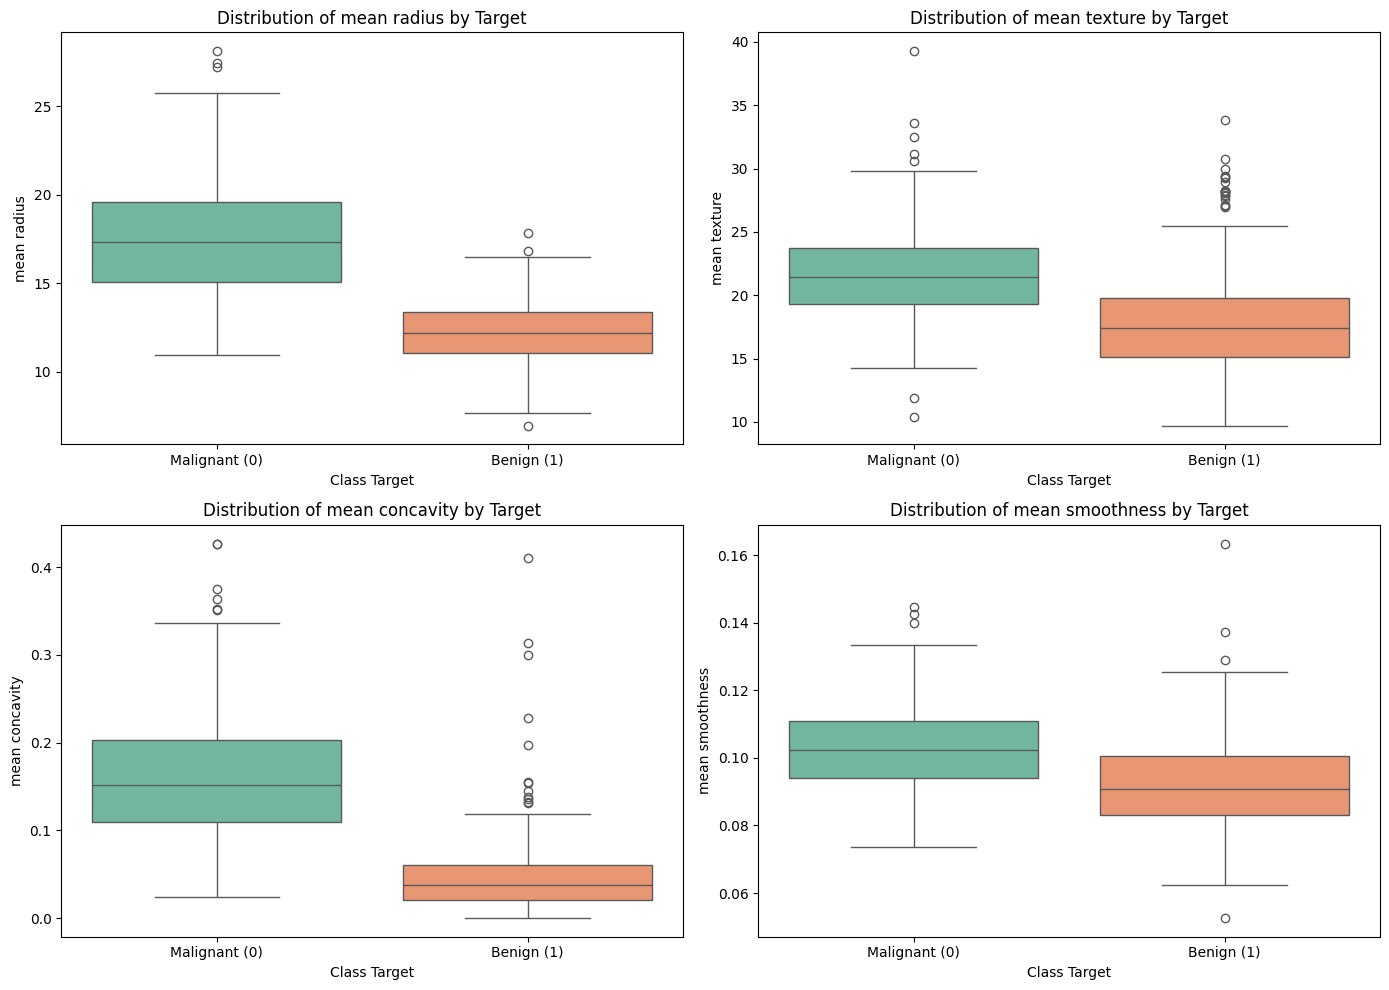

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(ax=axes[i], x='target', y=feature, data=df, palette='Set2')
    axes[i].set_title(f'Distribution of {feature} by Target')
    axes[i].set_xticklabels(['Malignant (0)', 'Benign (1)'])
    axes[i].set_xlabel('Class Target')
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

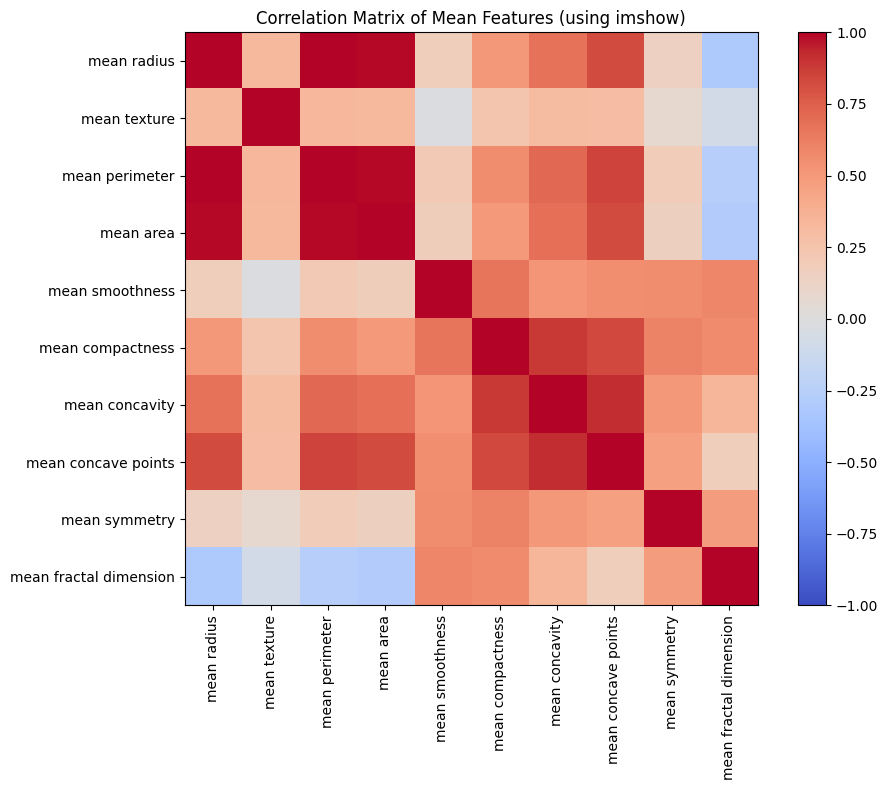

In [13]:
import numpy as np
import matplotlib.pyplot as plt


mean_features_df = df.filter(like="mean")
corr_matrix = mean_features_df.corr()

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest', vmin=-1, vmax=1)

plt.colorbar(im)

ticks = np.arange(len(corr_matrix.columns))
plt.xticks(ticks, corr_matrix.columns, rotation=90)
plt.yticks(ticks, corr_matrix.columns)

plt.title('Correlation Matrix of Mean Features (using imshow)')
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

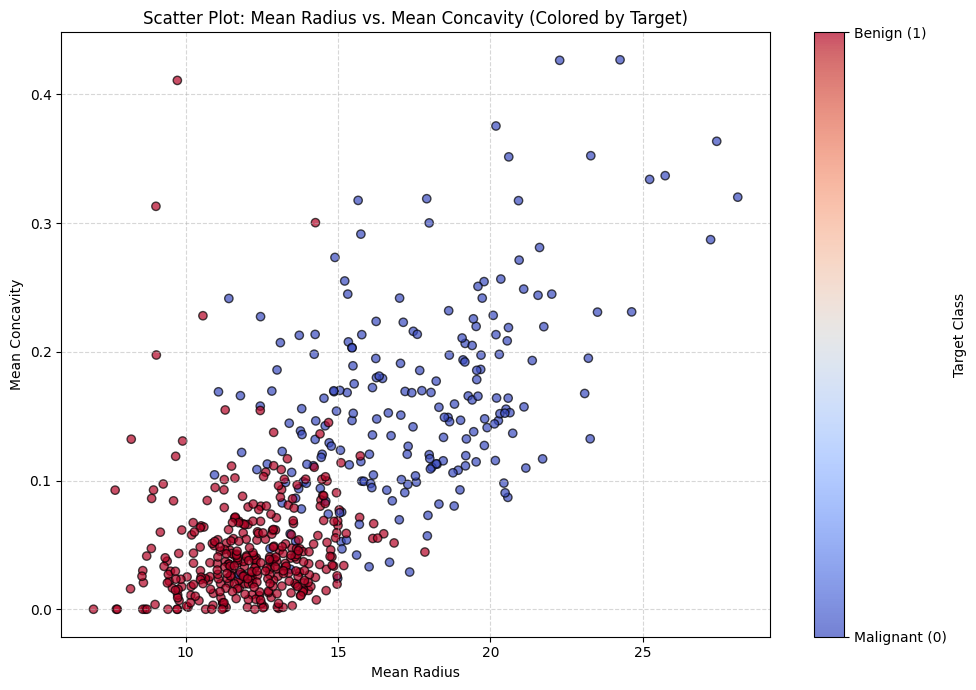

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df['mean radius'],
    df['mean concavity'],
    c=df['target'],
    cmap='coolwarm',
    alpha=0.7,
    edgecolors='k'
)

plt.xlabel('Mean Radius')
plt.ylabel('Mean Concavity')
plt.title('Scatter Plot: Mean Radius vs. Mean Concavity (Colored by Target)')

cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_ticklabels(['Malignant (0)', 'Benign (1)'])
cbar.set_label('Target Class')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:**

**Redundancies**: There are strong structural redundancies among the size-related features, as mean radius, mean perimeter, and mean area are almost perfectly correlated with one another. Similarly, contour-related properties like mean compactness, mean concavity, and mean concave points exhibit high linear correlation, indicating they capture overlapping geometric information.


**Class Separation**: Features measuring physical size and boundary irregularities, such as mean radius and mean concavity, show the clearest and most pronounced separation between benign and malignant classes. Conversely, features like mean smoothness and mean texture have heavily overlapping distributions, making them weaker predictors on their own.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [15]:
missing_values = df.isnull().sum().sum()

duplicated_rows = df.duplicated().sum()

print(f"Total missing values: {missing_values}")
print(f"Total duplicated rows: {duplicated_rows}")

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [16]:

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

outliers_count = outliers.sum().sort_values(ascending=False)

print("Top 10 features with the most IQR outliers:")
print(outliers_count.head(10))

Top 10 features with the most IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:**
No, we should not delete these outlying rows.

 **Real Biological Variation**: In clinical and diagnostic medical datasets, outliers represent real physical variation in aggressive or advanced tumors (e.g., extremely large sizes, extreme irregularity), rather than data entry errors.

**Critical Class Signal**: Deleting outliers would remove the most distinct signs of severe malignancy, drastically hurting our model's ability to identify true positive cancer cases (Recall/Sensitivity).

**Alternative Handling**: Instead of deletion, we can use robust scaling methods (like `RobustScaler`), non-linear transformations (such as log transforms), or models that are robust to outliers (like Tree-based ensemble classifiers).

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [17]:

corr_matrix = X.corr().abs()


upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))


to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

print(f"Number of features with absolute correlation > 0.95: {len(to_drop)}")
print("Features to drop due to high correlation:", to_drop)

Number of features with absolute correlation > 0.95: 7
Features to drop due to high correlation: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [18]:

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)


kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)

print("Top 10 features selected by SelectKBest (f_classif):")
display(kbest_scores.head(10))

kbest_features = kbest_scores.head(10).index.tolist()

Top 10 features selected by SelectKBest (f_classif):


,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [19]:

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

lr = LogisticRegression(random_state=7, max_iter=1000)

selector_rfe = RFE(estimator=lr, n_features_to_select=10)
selector_rfe.fit(X_scaled, y)

rfe_features = X.columns[selector_rfe.support_].tolist()

print("Top 10 features selected by RFE (Logistic Regression):")
print(rfe_features)

Top 10 features selected by RFE (Logistic Regression):
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

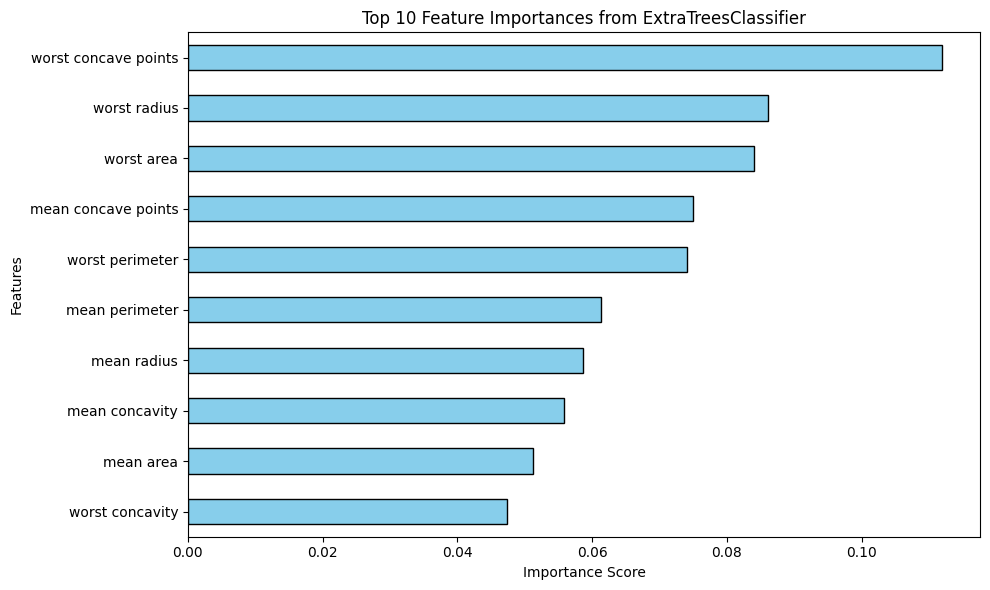

In [20]:
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
imp.tail(10).plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Top 10 Feature Importances from ExtraTreesClassifier')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


et_features = imp.tail(10).index.tolist()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [21]:
from collections import Counter

# Combine all three feature sets
all_selected_features = kbest_features + rfe_features + et_features

# Count the frequency of each feature
feature_counts = Counter(all_selected_features)

# Keep features selected by at least 2 methods
selected = [feature for feature, count in feature_counts.items() if count >= 2]

print(f"Number of final selected features: {len(selected)}")
print("Selected features:")
for feature in selected:
    print(f"- {feature} (selected by {feature_counts[feature]} methods)")

Number of final selected features: 10
Selected features:
- worst concave points (selected by 3 methods)
- worst perimeter (selected by 3 methods)
- mean concave points (selected by 3 methods)
- worst radius (selected by 3 methods)
- mean perimeter (selected by 2 methods)
- worst area (selected by 3 methods)
- mean radius (selected by 2 methods)
- mean area (selected by 2 methods)
- mean concavity (selected by 2 methods)
- worst concavity (selected by 3 methods)


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=7
)

print("X_train shape, X_test shape:")
print(X_train.shape, X_test.shape)

X_train shape, X_test shape:
(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [23]:
# Initialize the scalers
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Fit and transform on training data only
X_train_std = pd.DataFrame(std_scaler.fit_transform(X_train), columns=X_train.columns)
X_train_minmax = pd.DataFrame(minmax_scaler.fit_transform(X_train), columns=X_train.columns)

# Get the first four features
first_four_features = X_train.columns[:4].tolist()

print("=== Original Training Data Statistics (First 4 Features) ===")
display(X_train[first_four_features].agg(['mean', 'std', 'min', 'max']))

print("\n=== StandardScaler Training Data Statistics (First 4 Features) ===")
print("Expected: Mean ~ 0, Std ~ 1")
display(X_train_std[first_four_features].agg(['mean', 'std', 'min', 'max']))

print("\n=== MinMaxScaler Training Data Statistics (First 4 Features) ===")
print("Expected: Min = 0, Max = 1")
display(X_train_minmax[first_four_features].agg(['mean', 'std', 'min', 'max']))

=== Original Training Data Statistics (First 4 Features) ===


,mean radius,mean texture,mean perimeter,mean area
mean,14.033989,19.330593,91.328484,644.779560
std,3.418139,4.375076,23.485102,335.949232
min,6.981000,9.710000,43.790000,143.500000
max,27.420000,39.280000,186.900000,2501.000000



=== StandardScaler Training Data Statistics (First 4 Features) ===
Expected: Mean ~ 0, Std ~ 1


,mean radius,mean texture,mean perimeter,mean area
mean,9.369794e-17,-3.747918e-16,-5.797560e-16,-3.279428e-16
std,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00
min,-2.065671e+00,-2.201375e+00,-2.026426e+00,-1.493771e+00
max,3.920480e+00,4.564804e+00,4.073932e+00,5.531382e+00



=== MinMaxScaler Training Data Statistics (First 4 Features) ===
Expected: Min = 0, Max = 1


,mean radius,mean texture,mean perimeter,mean area
mean,0.345075,0.325350,0.332181,0.212632
std,0.167236,0.147957,0.164105,0.142502
min,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

Number of components that retain at least 95% variance: 10


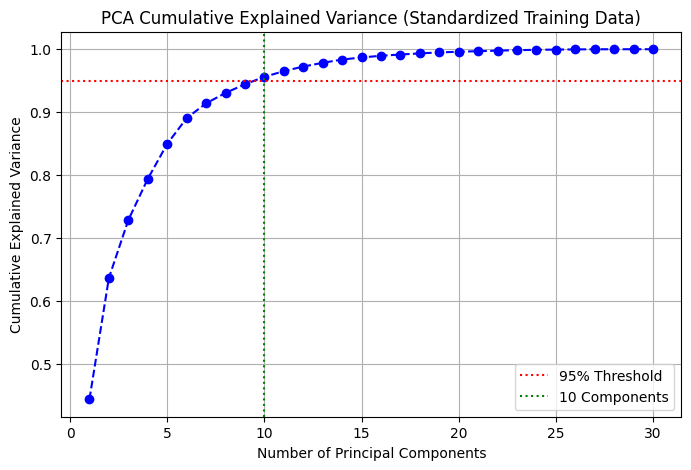

In [24]:
pca = PCA()
pca.fit(X_train_std)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Number of components that retain at least 95% variance: {n_components_95}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle=':', label='95% Threshold')
plt.axvline(x=n_components_95, color='g', linestyle=':', label=f'{n_components_95} Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance (Standardized Training Data)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [25]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(random_state=seed, max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [26]:
results_raw = spot_check(models, X_train, scale=False)
results_scaled = spot_check(models, X_train, scale=True)

mean_raw = {name: scores.mean() for name, scores in results_raw.items()}
mean_scaled = {name: scores.mean() for name, scores in results_scaled.items()}

summary = pd.DataFrame({
    'raw': pd.Series(mean_raw),
    'scaled': pd.Series(mean_scaled)
})

display(summary)

,raw,scaled
LR,0.944976,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:**

Based on the spot-check comparative results, **Logistic Regression (LR)**, **K-Nearest Neighbors (KNN)**, and **Support Vector Machine (SVM)** benefit significantly from feature scaling (standardization):

1. **Distance-Based Algorithms (KNN & SVM)**:
   * **KNN** relies on calculating Euclidean distances between instances. Features with larger raw magnitudes (such as `mean area` ranging up to 2500) would dominate the distance calculation compared to features with tiny ranges (like `smoothness` below 0.2), rendering the smaller features functionally useless.
   * **SVM** aims to maximize the margin between classes. Optimization algorithms inside SVM rely heavily on gradient descent-like computations and are sensitive to feature scales, which can lead to slow convergence or biased decision boundaries towards large-scale features.

2. **Gradient/Regularization-Based Algorithms (Logistic Regression)**:
   * **LR** uses $L_2$ regularization by default. Regularization applies a penalty to coefficient magnitudes equally. If features are not on the same scale, the penalties will unfairly target features with smaller scales (as their coefficients must be larger to compensate for their scale).

### Models Insensitive to Scaling
* **Decision Trees (CART)**: Tree splits are determined by thresholds on individual features independently, meaning scale transformations do not alter the ordering or structural relationships.
* **Naive Bayes (NB)**: Estimates class-conditional probability distributions independently for each feature, making it highly robust to scale discrepancies.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [27]:
results_selected = spot_check(models, X_train[selected], scale=True)
mean_selected = {name: scores.mean() for name, scores in results_selected.items()}

comparison_df = pd.DataFrame({
    'all_features_scaled': summary['scaled'],
    'selected_features_scaled': pd.Series(mean_selected)
})

display(comparison_df)

,all_features_scaled,selected_features_scaled
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.925266
NB,0.932029,0.951691
SVM,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

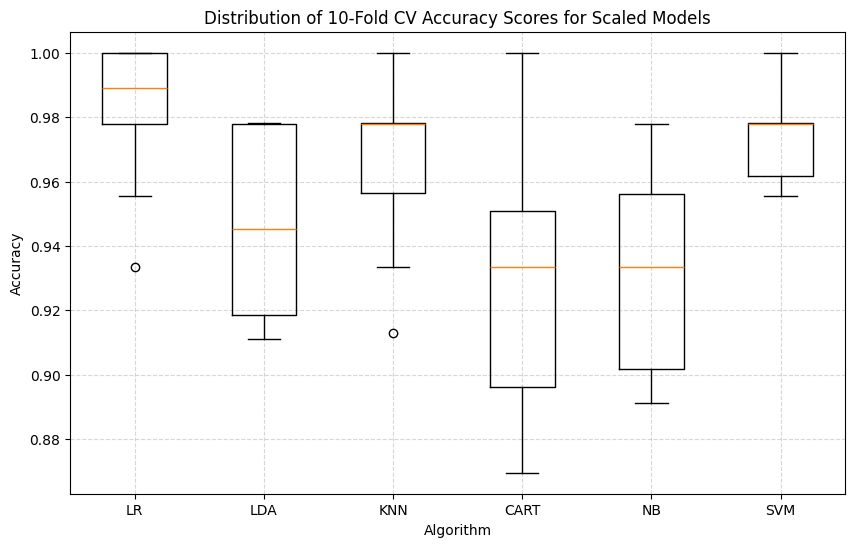

In [28]:
plt.figure(figsize=(10, 6))
plt.boxplot(results_scaled.values(), labels=results_scaled.keys())
plt.title('Distribution of 10-Fold CV Accuracy Scores for Scaled Models')
plt.ylabel('Accuracy')
plt.xlabel('Algorithm')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [29]:
scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'recall_malignant': make_scorer(recall_score, pos_label=0)
}

best_model = LogisticRegression(random_state=seed, max_iter=1000)
pipeline = Pipeline([('scale', StandardScaler()), ('model', best_model)])

cv_results = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)

print(f"Mean CV Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean CV ROC-AUC: {cv_results['test_roc_auc'].mean():.4f}")
print(f"Mean CV Recall (Malignant, Class 0): {cv_results['test_recall_malignant'].mean():.4f}")

Mean CV Accuracy: 0.9823
Mean CV ROC-AUC: 0.9922
Mean CV Recall (Malignant, Class 0): 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [30]:
param_grid = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.001, 0.01, 0.1],
    'model__kernel': ['rbf', 'linear']
}

pipeline = Pipeline([('scale', StandardScaler()), ('model', SVC(random_state=seed))])
grid_search_svm = GridSearchCV(pipeline, param_grid, cv=kfold, scoring='accuracy', n_jobs=-1)
grid_search_svm.fit(X_train, y_train)

print(f"Best SVM Parameters: {grid_search_svm.best_params_}")
print(f"Best SVM CV Accuracy: {grid_search_svm.best_score_:.4f}")

Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [31]:
param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'model__weights': ['uniform', 'distance']
}

pipeline_knn = Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier())])
grid_search_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=kfold, scoring='accuracy', n_jobs=-1)
grid_search_knn.fit(X_train, y_train)

print(f"Best KNN Parameters: {grid_search_knn.best_params_}")
print(f"Best KNN CV Accuracy: {grid_search_knn.best_score_:.4f}")

Best KNN Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [32]:
ensembles = {
    'RF': RandomForestClassifier(random_state=seed),
    'ET': ExtraTreesClassifier(random_state=seed),
    'GB': GradientBoostingClassifier(random_state=seed),
    'AB': AdaBoostClassifier(random_state=seed)
}

ensembles_results = spot_check(ensembles, X_train, scale=False)

tuned_svm = SVC(C=grid_search_svm.best_params_['model__C'],
                gamma=grid_search_svm.best_params_['model__gamma'],
                kernel=grid_search_svm.best_params_['model__kernel'],
                random_state=seed)

tuned_knn = KNeighborsClassifier(n_neighbors=grid_search_knn.best_params_['model__n_neighbors'],
                                 weights=grid_search_knn.best_params_['model__weights'])

rf_base = RandomForestClassifier(random_state=seed)

scaled_svm = Pipeline([('scale', StandardScaler()), ('model', tuned_svm)])
scaled_knn = Pipeline([('scale', StandardScaler()), ('model', tuned_knn)])

voting_clf = VotingClassifier(
    estimators=[
        ('svm', scaled_svm),
        ('knn', scaled_knn),
        ('rf', rf_base)
    ],
    voting='hard'
)

voting_scores = cross_val_score(voting_clf, X_train, y_train, cv=kfold, scoring='accuracy')

for name, scores in ensembles_results.items():
    print(f"{name} Mean Accuracy: {scores.mean():.4f}")
print(f"Voting Ensemble Mean Accuracy: {voting_scores.mean():.4f}")

RF Mean Accuracy: 0.9691
ET Mean Accuracy: 0.9736
GB Mean Accuracy: 0.9670
AB Mean Accuracy: 0.9626
Voting Ensemble Mean Accuracy: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [33]:
leaderboard_data = {
    'Tuned SVM': grid_search_svm.best_score_,
    'Tuned KNN': grid_search_knn.best_score_,
    'Random Forest (RF)': ensembles_results['RF'].mean(),
    'Extra Trees (ET)': ensembles_results['ET'].mean(),
    'Gradient Boosting (GB)': ensembles_results['GB'].mean(),
    'AdaBoost (AB)': ensembles_results['AB'].mean(),
    'Voting Ensemble': voting_scores.mean()
}

leaderboard = pd.Series(leaderboard_data).sort_values(ascending=False)
print("=== Model Leaderboard (Mean CV Accuracy) ===")
display(leaderboard)

=== Model Leaderboard (Mean CV Accuracy) ===


,0
Tuned SVM,0.980193
Voting Ensemble,0.978068
Extra Trees (ET),0.973575
Tuned KNN,0.969275
Random Forest (RF),0.969130
Gradient Boosting (GB),0.966957
AdaBoost (AB),0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

=== Final Test Evaluation ===
Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



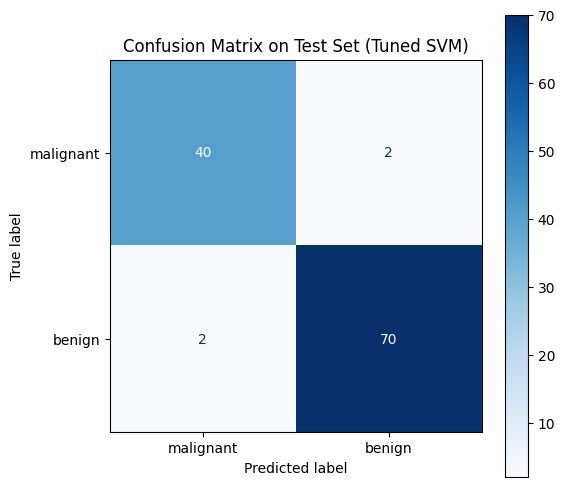

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Re-create and train the winning model (Tuned SVM with scaling)
winning_svm = SVC(
    C=grid_search_svm.best_params_['model__C'],
    gamma=grid_search_svm.best_params_['model__gamma'],
    kernel=grid_search_svm.best_params_['model__kernel'],
    random_state=seed
)

winner_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', winning_svm)
])

winner_pipeline.fit(X_train, y_train)

# 2. Predict on the held-out test set
y_pred = winner_pipeline.predict(X_test)

# 3. Report evaluation metrics
test_acc = accuracy_score(y_test, y_pred)
print(f"=== Final Test Evaluation ===")
print(f"Test Accuracy: {test_acc:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# 4. Display the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title("Confusion Matrix on Test Set (Tuned SVM)")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [35]:
import joblib

# 1. Save the model to a file
model_filename = 'final_svm_model.joblib'
joblib.dump(winner_pipeline, model_filename)
print(f"Model successfully saved to '{model_filename}'")

# 2. Reload the model
loaded_pipeline = joblib.load(model_filename)
print("Model successfully reloaded")

# 3. Make predictions using the loaded model
y_pred_loaded = loaded_pipeline.predict(X_test)

# 4. Verify predictions match the original pipeline's predictions
assert (y_pred == y_pred_loaded).all(), "Error: Loaded model predictions do not match the original model's predictions!"
print("Assertion passed: Reloaded model predictions perfectly match original predictions.\n")

# 5. Display and compare the first 5 predictions with actual y_test labels
comparison_results = pd.DataFrame({
    'Actual y_test': y_test.head(5),
    'Predicted': y_pred_loaded[:5]
})

print("Comparison of the first 5 test set predictions:")
display(comparison_results)

Model successfully saved to 'final_svm_model.joblib'
Model successfully reloaded
Assertion passed: Reloaded model predictions perfectly match original predictions.

Comparison of the first 5 test set predictions:


,Actual y_test,Predicted
167,0,0
283,0,0
152,1,1
156,0,0
97,1,1
